# Task 3 (Reproduction): DDRNet-23-slim on CamVid

Reproducing **DDRNet-23-slim** on CamVid (`960x720`, 11 classes), verifying both the official checkpoint (`DDRNet23s_camvid.pth`) and an 8-epoch CPU scratch run.

In [ ]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch

CWD = Path(".").resolve()
REPO_ROOT = CWD if (CWD / "DDRNet").exists() else CWD.parent
DDRNET_DIR = REPO_ROOT / "DDRNet"
for p in [str(DDRNET_DIR), str(DDRNET_DIR / "segmentation")]:
    if p not in sys.path:
        sys.path.insert(0, p)

from DDRNet_23_slim import DualResNet, BasicBlock
from datasets.camvid import CamVid
from benchmarks import get_hardware_info, profile_parameters, profile_flops, benchmark_inference_speed
from train_camvid import resolve_camvid_root, run_training, plot_training_history
from test_camvid import run_testing

DATA_ROOT = resolve_camvid_root()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")

Device: cpu | PyTorch: 2.14.0+cpu


## 1. Model, Complexity & Speed

In [ ]:
model = DualResNet(BasicBlock, [2, 2, 2, 2], num_classes=11, planes=32, spp_planes=128, head_planes=64, augment=False).to(device).eval()

with torch.no_grad():
    out = model(torch.randn(1, 3, 720, 960, device=device))
print("Input: (1, 3, 720, 960) -> Output:", tuple(out.shape))

param_info = profile_parameters(model)
flop_profiles = profile_flops(model, [(720, 960)], device=device)
hw_info = get_hardware_info(device)
speed = benchmark_inference_speed(model, input_resolution=(720, 960), batch_size=1, device=device, warmup_runs=5, timed_runs=15)

print(f"Params: {param_info['total_params_M']:.2f} M | Hardware: {hw_info['CPU_Processor']}")
print(f"FLOPs (960x720): {flop_profiles[0]['FLOPs_G']:.2f} G | Latency: {speed['Mean_Latency_ms']:.1f} ms | FPS: {speed['FPS']:.2f}")

Input: (1, 3, 720, 960) -> Output: (1, 11, 90, 120)


Params: 5.70 M | Hardware: Intel64 Family 6 Model 154 Stepping 4, GenuineIntel
FLOPs (960x720): 24.28 G | Latency: 266.1 ms | FPS: 3.76


## 2. Training (CamVid, 8 Epochs CPU Scratch)

Loaded 8-epoch history from training_history.json


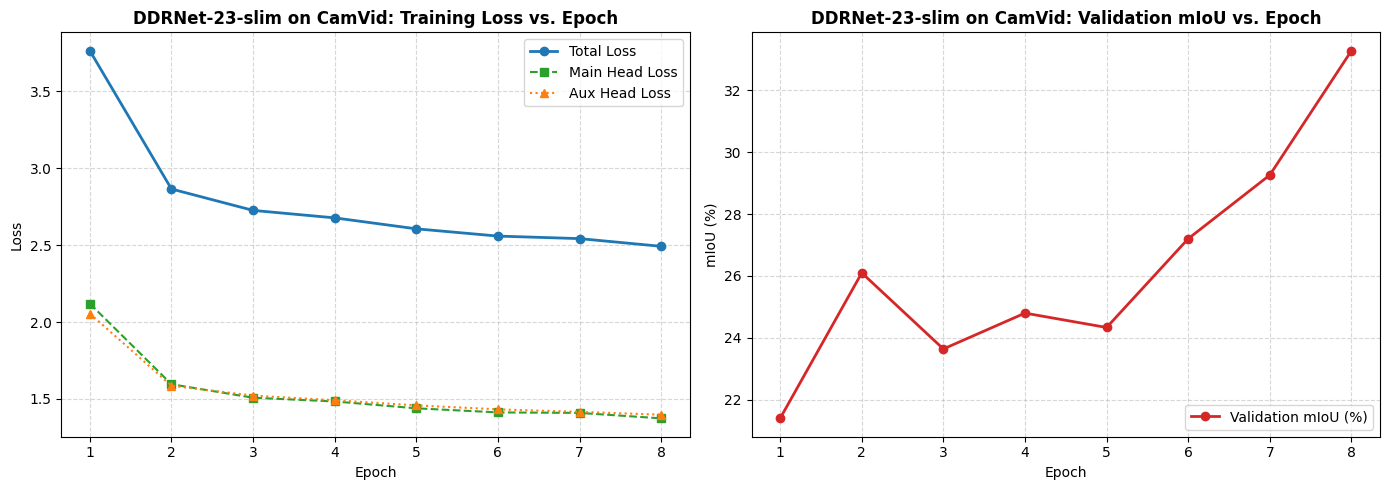

In [ ]:
TRAIN_CONFIG = {
    "epochs": 200,
    "batch_size": 4,
    "optimizer": "adamw",
    "base_lr": 0.001,
    "aux_weight": 0.8,
    "crop_size": (288, 384),
    "val_freq": 1,
    "val_samples": 50,
    "save_dir": str(REPO_ROOT / "output" / "camvid_ddrnet_train"),
}

RETRAIN = False  # Set True to re-run training
history_path = Path(TRAIN_CONFIG["save_dir"]) / "training_history.json"
ckpt_path = Path(TRAIN_CONFIG["save_dir"]) / "best_ddrnet_camvid.pt"

if RETRAIN or not (history_path.exists() and ckpt_path.exists()):
    history = run_training(
        data_root=DATA_ROOT,
        train_list="list/camvid/train.lst",
        val_list="list/camvid/val.lst",
        epochs=TRAIN_CONFIG["epochs"],
        batch_size=TRAIN_CONFIG["batch_size"],
        optimizer_name=TRAIN_CONFIG["optimizer"],
        base_lr=TRAIN_CONFIG["base_lr"],
        aux_weight=TRAIN_CONFIG["aux_weight"],
        crop_h=TRAIN_CONFIG["crop_size"][0],
        crop_w=TRAIN_CONFIG["crop_size"][1],
        val_freq=TRAIN_CONFIG["val_freq"],
        val_samples=TRAIN_CONFIG["val_samples"],
        save_dir=TRAIN_CONFIG["save_dir"],
    )
else:
    history = json.loads(history_path.read_text())
    print(f"Loaded {len(history)}-epoch history from {history_path.name}")

plot_training_history(history)
plt.show()

## 3. Test Set Evaluation (Official Checkpoint vs. CPU Scratch, N=233)

In [ ]:
official_ckpt = DDRNET_DIR / "pretrained_models" / "DDRNet23s_camvid.pth"
official_out_dir = REPO_ROOT / "output" / "camvid_ddrnet_official_test"
trained_out_dir = REPO_ROOT / "output" / "camvid_ddrnet_test"

official_json = official_out_dir / "test_metrics_summary.json"
official_summary = json.loads(official_json.read_text()) if official_json.exists() else run_testing(
    data_root=DATA_ROOT, test_list="list/camvid/test.lst",
    weights_path=str(official_ckpt), output_dir=str(official_out_dir), num_samples=None, official_mode=True,
)

trained_summary = run_testing(
    data_root=DATA_ROOT, test_list="list/camvid/test.lst",
    weights_path=str(ckpt_path), output_dir=str(trained_out_dir), batch_size=2, num_samples=None, official_mode=False,
)

display(pd.DataFrame([
    {"Run": "Official DDRNet23s_camvid.pth", "mIoU (%)": official_summary["mIoU_percent"], "Dice (%)": official_summary["mean_Dice_percent"], "Sensitivity (%)": official_summary["mean_Sensitivity_percent"], "Specificity (%)": official_summary["mean_Specificity_percent"], "Pixel Acc (%)": official_summary["Pixel_Accuracy_percent"]},
    {"Run": "CPU 8-Epoch Scratch", "mIoU (%)": trained_summary["mIoU_percent"], "Dice (%)": trained_summary["mean_Dice_percent"], "Sensitivity (%)": trained_summary["mean_Sensitivity_percent"], "Specificity (%)": trained_summary["mean_Specificity_percent"], "Pixel Acc (%)": trained_summary["Pixel_Accuracy_percent"]},
]))

DDRNET-23-SLIM EVALUATION ON CAMVID TEST SET (960x720)
[INFO] Device: cpu | Official Checkpoint Mode: False
[INFO] Checkpoint: C:\Users\gitan\Desktop\AI Project\output\camvid_ddrnet_train\best_ddrnet_camvid.pt


[INFO] Loaded checkpoint: C:\Users\gitan\Desktop\AI Project\output\camvid_ddrnet_train\best_ddrnet_camvid.pt



Testing DDRNet:   0%|          | 0/117 [00:00<?, ?it/s]


Testing DDRNet:   1%|          | 1/117 [00:02<04:56,  2.56s/it]


Testing DDRNet:   2%|▏         | 2/117 [00:05<04:53,  2.55s/it]


Testing DDRNet:   3%|▎         | 3/117 [00:07<04:38,  2.44s/it]

... (112 outputs left out)


Testing DDRNet:  99%|█████████▉| 116/117 [02:50<00:01,  1.62s/it]


Testing DDRNet: 100%|██████████| 117/117 [02:51<00:00,  1.37s/it]


CAMVID TEST EVALUATION RESULTS (DDRNet-23-slim):
  Mean IoU (mIoU):           26.15%
  Mean Dice Score (F1):      35.02%
  Mean Sensitivity (Recall): 33.84%
  Mean Specificity:          96.22%
  Overall Pixel Accuracy:    66.29%
  Valid Pixels Evaluated:    155,344,711


,Run,mIoU (%),Dice (%),Sensitivity (%),Specificity (%),Pixel Acc (%)
0,Official DDRNet23s_camvid.pth,56.02,68.96,65.94,98.46,86.39
1,CPU 8-Epoch Scratch,26.15,35.02,33.84,96.22,66.29


## 4. Per-Class Breakdown & Sample Predictions

,Class,Pixels_GT,CPU_8Ep_IoU (%),Official_IoU (%),Official_Dice (%)
0,Bicyclist,304725,0.00,31.61,48.03
1,Building,39662356,51.13,75.80,86.23
2,Car,6783536,22.42,65.46,79.12
3,Pole,1896657,0.18,32.34,48.87
4,Fence,1908067,1.36,26.95,42.46
5,Pedestrian,1091081,3.66,48.80,65.59
6,Road,41124851,64.01,85.24,92.03
7,Sidewalk,15263757,27.94,58.66,73.94
8,SignSymbol,1625166,2.66,26.90,42.40
9,Sky,27548390,69.34,91.77,95.71


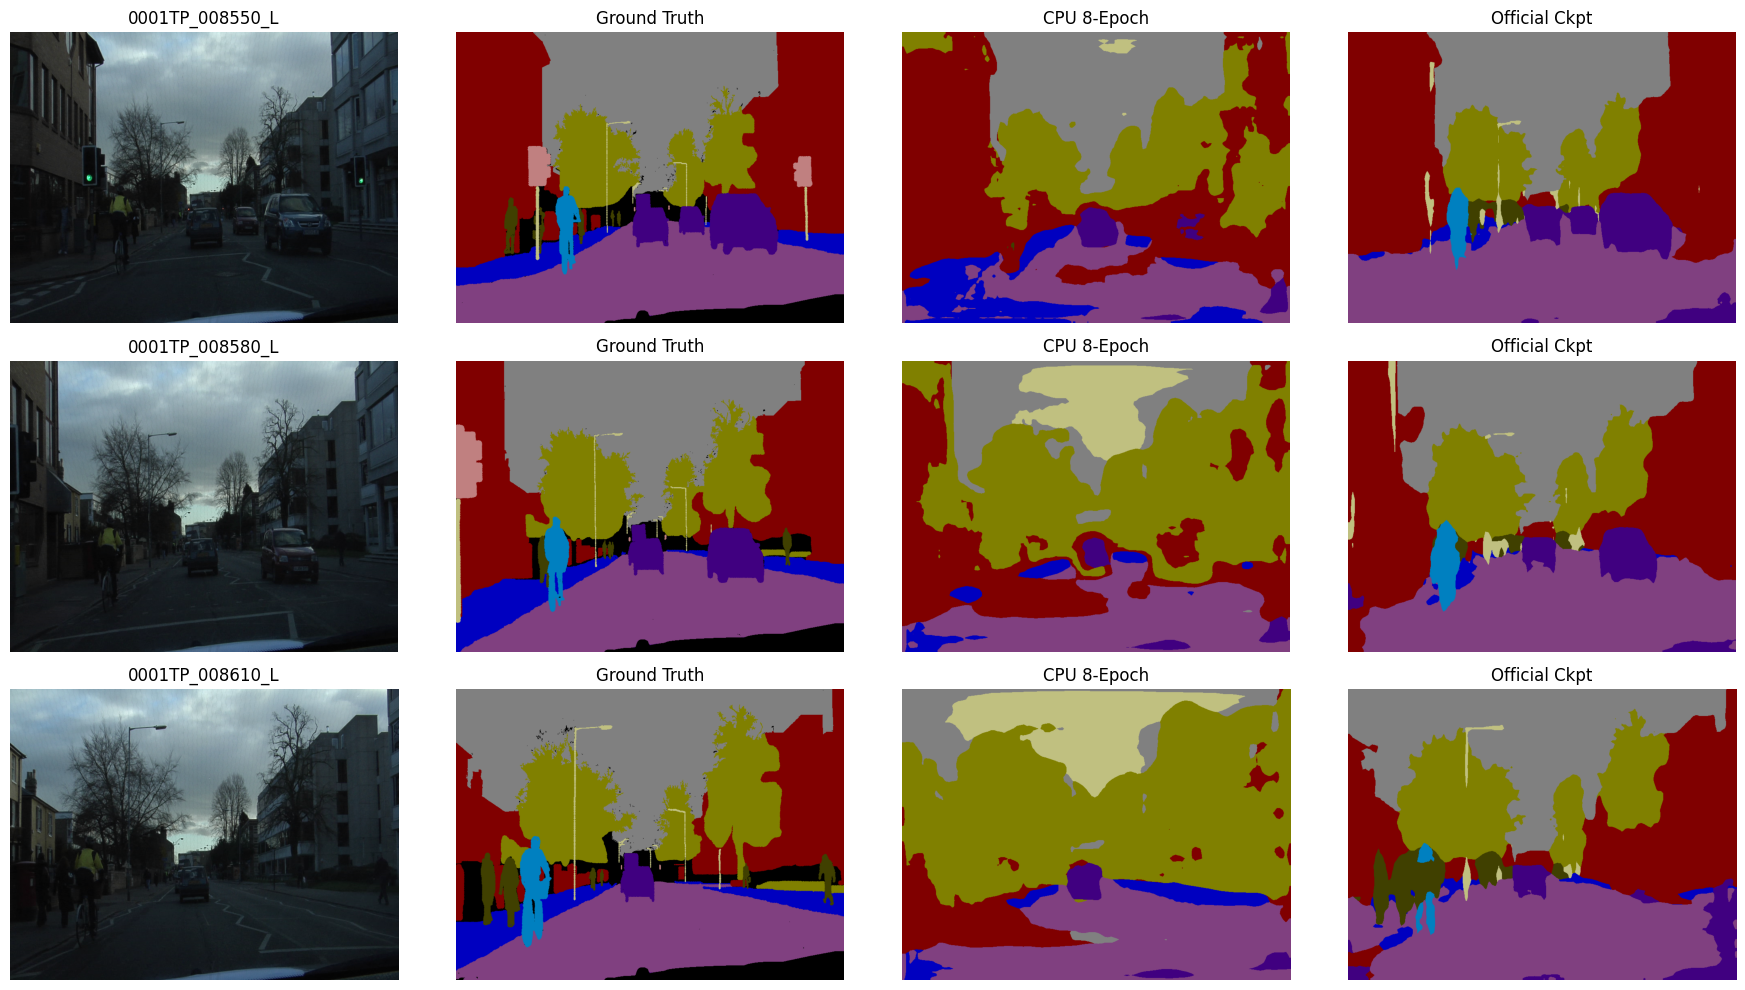

In [ ]:
df_tr = pd.read_csv(trained_out_dir / "test_per_class_metrics.csv")
df_off = pd.read_csv(official_out_dir / "test_per_class_metrics.csv")
display(pd.DataFrame({
    "Class": df_tr["Class_Name"],
    "Pixels_GT": df_tr["Pixels_GT"],
    "CPU_8Ep_IoU (%)": df_tr["IoU (%)"].round(2),
    "Official_IoU (%)": df_off["IoU (%)"].round(2),
    "Official_Dice (%)": df_off["Dice (%)"].round(2),
}))

test_ds = CamVid(root=DATA_ROOT, list_path="list/camvid/test.lst", num_classes=11, multi_scale=False, flip=False, base_size=960, crop_size=(720, 960))
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for i, item in enumerate(test_ds.files[:3]):
    raw_img = np.array(Image.open(os.path.join(DATA_ROOT, "camvid", item["img"])).convert("RGB"))
    gt_col = np.array(Image.open(os.path.join(DATA_ROOT, "camvid", item["label"])).convert("RGB"))
    pred_cpu = np.array(Image.open(trained_out_dir / "predicted_masks" / f"{item['name']}_pred.png"))
    pred_off = np.array(Image.open(official_out_dir / "predicted_masks" / f"{item['name']}_pred.png"))
    axes[i, 0].imshow(raw_img); axes[i, 0].set_title(item["name"]); axes[i, 0].axis("off")
    axes[i, 1].imshow(gt_col); axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")
    axes[i, 2].imshow(pred_cpu); axes[i, 2].set_title("CPU 8-Epoch"); axes[i, 2].axis("off")
    axes[i, 3].imshow(pred_off); axes[i, 3].set_title("Official Ckpt"); axes[i, 3].axis("off")
plt.tight_layout()
plt.show()

## 5. Paper vs. Reproduction Comparison

In [ ]:
display(pd.DataFrame({
    "Metric": ["Params", "Test mIoU (N=233)", "Pixel Accuracy", "Speed"],
    "Paper (Hong et al., 2022)": ["5.70 M", "74.7% (ImageNet) / 78.6% (Cityscapes)", "?", "230 FPS (RTX 2080Ti)"],
    "Official Ckpt (CPU)": [f"{param_info['total_params_M']:.2f} M", f"{official_summary['mIoU_percent']:.2f}%", f"{official_summary['Pixel_Accuracy_percent']:.2f}%", f"{speed['FPS']:.2f} FPS (CPU)"],
    "CPU 8-Epoch Scratch": [f"{param_info['total_params_M']:.2f} M", f"{trained_summary['mIoU_percent']:.2f}%", f"{trained_summary['Pixel_Accuracy_percent']:.2f}%", f"{speed['FPS']:.2f} FPS (CPU)"],
}))

,Metric,"Paper (Hong et al., 2022)",Official Ckpt (CPU),CPU 8-Epoch Scratch
0,Params,5.70 M,5.70 M,5.70 M
1,Test mIoU (N=233),74.7% (ImageNet) / 78.6% (Cityscapes),56.02%,26.15%
2,Pixel Accuracy,?,86.39%,66.29%
3,Speed,230 FPS (RTX 2080Ti),3.76 FPS (CPU),3.76 FPS (CPU)
